# Baselines: how well can pixel models predict urban heat, and what does hyperspectral add?

**Target:** the **LST anomaly**: each pixel's land surface temperature minus its scene's median (°C). This removes the
day's weather and climate (88 % of the variance, see `01_dataset_overview`) and leaves the part the surface
controls, which is what mitigation can change. An absolute-LST model is at the end for comparison.

**Evaluation:** train on the train split, early-stop on val, report **test**: cities never seen in training
(Member 1's split by location). Pixels come from the dataset's pixel table (2,000 random valid pixels per pair).

**Ablation**, the core question of the project: the same XGBoost model with growing inputs:

| Feature set | Inputs |
|---|---|
| `landsat` | Landsat bands + NDVI/NDBI/MNDWI, built-up share, relative elevation, slope, sensor |
| `landsat+hs_indices` | + 4 hyperspectral indices: albedo, red-edge, leaf water (860/1240 nm), SWIR 2200 nm absorption |
| `landsat+hs_bands` | + all 122 hyperspectral bands |
| `thermal_only` | only the thermal context (where it is *usually* hot) |
| `landsat+thermal` | Landsat set + thermal context |
| `all` | everything |

In [1]:
import json, numpy as np, pandas as pd, matplotlib.pyplot as plt
from pathlib import Path
from urbanheat.config import load_config
from urbanheat.models import features as F, baselines as B

cfg = load_config()
H5 = Path(cfg["data"]["processed_dir"]) / f"urbanheat_v{cfg['harmonize']['version']}.h5"
RUNS = Path(cfg["runs_dir"])
plt.rcParams["figure.dpi"] = 90
pd.set_option("display.precision", 3)

X, info, hs_cols = F.table(H5)
print(f"pixel table: {len(X):,} pixels x {X.shape[1]} features |", info.split.value_counts().to_dict())

pixel table: 842,935 pixels x 150 features | {'train': 640935, 'test': 112000, 'val': 90000}


## Reference: predicting zero

Predicting "every pixel is at its scene median" has R² ≈ 0. Its MAE is the typical size of the anomaly.

In [2]:
y = info.y_anom.to_numpy()
te = (info.split == "test").to_numpy()
print("zero predictor on test:", {k: round(v, 3) for k, v in B.scores(y[te], np.zeros(te.sum())).items()})

zero predictor on test: {'mae': 2.178, 'rmse': 2.991, 'r2': -0.0, 'n': 112000}


## Ablation with XGBoost (GPU)

In [3]:
results, models = {}, {}
for name, cols in F.feature_sets(hs_cols).items():
    m, models[name] = B.run(f"xgb_anom_{name}", "xgb", X[cols], y, info, RUNS, "anomaly", hardware="RTX 3050 6 GB")
    results[("xgb", name)] = m
    print(f"{name:20s} {len(cols):4d} features | test MAE {m['test']['mae']:.2f}  RMSE {m['test']['rmse']:.2f}  "
          f"R2 {m['test']['r2']:.3f} | val R2 {m['val']['r2']:.3f} | {m['train_seconds']:.0f}s")

C:\miniforge3\envs\pygile\lib\site-packages\xgboost\core.py:751: UserWarning: [15:50:55] WARNING: C:\actions-runner\_work\xgboost\xgboost\src\common\error_msg.cc:62: Falling back to prediction using DMatrix due to mismatched devices. This might lead to higher memory usage and slower performance. XGBoost is running on: cuda:0, while the input data is on: cpu.
Potential solutions:
- Use a data structure that matches the device ordinal in the booster.
- Set the device for booster before call to inplace_predict.

This warning will only be shown once.

  return func(**kwargs)


landsat                15 features | test MAE 1.93  RMSE 2.58  R2 0.254 | val R2 0.368 | 4s


landsat+hs_indices     19 features | test MAE 1.92  RMSE 2.57  R2 0.261 | val R2 0.383 | 9s


landsat+hs_bands      141 features | test MAE 1.88  RMSE 2.53  R2 0.284 | val R2 0.392 | 33s


thermal_only            4 features | test MAE 1.05  RMSE 1.56  R2 0.728 | val R2 0.665 | 2s


landsat+thermal        16 features | test MAE 1.05  RMSE 1.51  R2 0.744 | val R2 0.700 | 6s


all                   142 features | test MAE 1.05  RMSE 1.51  R2 0.744 | val R2 0.699 | 24s


## Other model types on the same inputs

Ridge regression (linear) and Random Forest (200 trees, trained on a 200 k-pixel subsample to keep it fast).

In [4]:
for kind in ["ridge", "rf"]:
    for name in ["landsat", "landsat+hs_bands", "all"]:
        cols = F.feature_sets(hs_cols)[name]
        m, _ = B.run(f"{kind}_anom_{name}", kind, X[cols], y, info, RUNS, "anomaly", max_train=200_000)
        results[(kind, name)] = m
        print(f"{kind:5s} {name:18s} test MAE {m['test']['mae']:.2f}  R2 {m['test']['r2']:.3f} | {m['train_seconds']:.0f}s")

ridge landsat            test MAE 1.92  R2 0.226 | 0s


C:\miniforge3\envs\pygile\lib\site-packages\sklearn\linear_model\_ridge.py:213: LinAlgWarning: Ill-conditioned matrix (rcond=2.20872e-08): result may not be accurate.
  return linalg.solve(A, Xy, assume_a="pos", overwrite_a=True).T


ridge landsat+hs_bands   test MAE 1.90  R2 0.245 | 1s


C:\miniforge3\envs\pygile\lib\site-packages\sklearn\linear_model\_ridge.py:213: LinAlgWarning: Ill-conditioned matrix (rcond=2.2029e-08): result may not be accurate.
  return linalg.solve(A, Xy, assume_a="pos", overwrite_a=True).T


ridge all                test MAE 1.03  R2 0.751 | 1s


rf    landsat            test MAE 1.91  R2 0.269 | 20s


rf    landsat+hs_bands   test MAE 1.90  R2 0.271 | 77s


rf    all                test MAE 1.30  R2 0.611 | 70s


In [5]:
table = pd.DataFrame([dict(model=k, features=n, n_features=m["n_features"], **{f"{s}_{q}": m[s][q] for s in ["val", "test"]
                                                                               for q in ["mae", "rmse", "r2"]})
                      for (k, n), m in results.items()])
table.sort_values("test_r2", ascending=False).reset_index(drop=True)

,model,features,n_features,val_mae,val_rmse,val_r2,test_mae,test_rmse,test_r2
0,ridge,all,142,1.001,1.435,0.688,1.028,1.492,0.751
1,xgb,all,142,0.976,1.409,0.699,1.049,1.513,0.744
2,xgb,landsat+thermal,16,0.971,1.406,0.700,1.046,1.514,0.744
3,xgb,thermal_only,4,1.020,1.486,0.665,1.053,1.559,0.728
4,rf,all,142,1.090,1.573,0.625,1.299,1.864,0.611
5,xgb,landsat+hs_bands,141,1.452,2.002,0.392,1.881,2.530,0.284
6,rf,landsat+hs_bands,141,1.498,2.073,0.348,1.896,2.554,0.271
7,rf,landsat,15,1.501,2.057,0.358,1.910,2.556,0.269
8,xgb,landsat+hs_indices,19,1.461,2.018,0.383,1.925,2.571,0.261
9,xgb,landsat,15,1.491,2.042,0.368,1.933,2.582,0.254


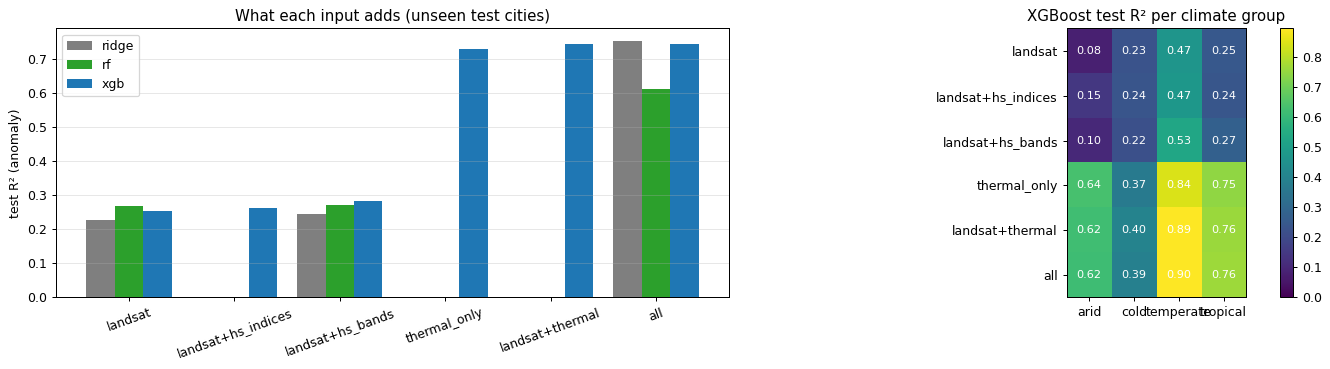

,EMIT,ENMAP,HYPERION
landsat,0.243,0.506,0.221
landsat+hs_indices,0.227,0.530,0.253
landsat+hs_bands,0.261,0.546,0.264
thermal_only,0.776,0.833,0.650
landsat+thermal,0.787,0.840,0.673
all,0.790,0.840,0.670


In [6]:
order = list(F.feature_sets(hs_cols))
fig, ax = plt.subplots(1, 2, figsize=(15, 4.2))
for kind, off, col in [("ridge", -0.27, "tab:gray"), ("rf", 0, "tab:green"), ("xgb", 0.27, "tab:blue")]:
    vals = [results.get((kind, n), {}).get("test", {}).get("r2", np.nan) for n in order]
    ax[0].bar(np.arange(len(order)) + off, vals, width=0.27, label=kind, color=col)
ax[0].set_xticks(range(len(order))); ax[0].set_xticklabels(order, rotation=20)
ax[0].set_ylabel("test R² (anomaly)"); ax[0].set_title("What each input adds (unseen test cities)"); ax[0].legend(); ax[0].grid(alpha=.3, axis="y")
pc = pd.DataFrame({n: {g: v["r2"] for g, v in results[("xgb", n)]["test"]["per_climate"].items()} for n in order}).T
im = ax[1].imshow(pc.values, cmap="viridis", vmin=0, vmax=max(0.6, np.nanmax(pc.values)))
ax[1].set_xticks(range(pc.shape[1])); ax[1].set_xticklabels(pc.columns); ax[1].set_yticks(range(len(order))); ax[1].set_yticklabels(order)
for i in range(pc.shape[0]):
    for j in range(pc.shape[1]):
        ax[1].text(j, i, f"{pc.values[i, j]:.2f}", ha="center", va="center", color="w", fontsize=9)
ax[1].set_title("XGBoost test R² per climate group"); plt.colorbar(im, ax=ax[1], fraction=0.046)
plt.tight_layout(); plt.show()
pd.DataFrame({n: {g: v["r2"] for g, v in results[("xgb", n)]["test"]["per_sensor"].items()} for n in order}).T.round(3)

## Predicted vs observed (best set, test cities)

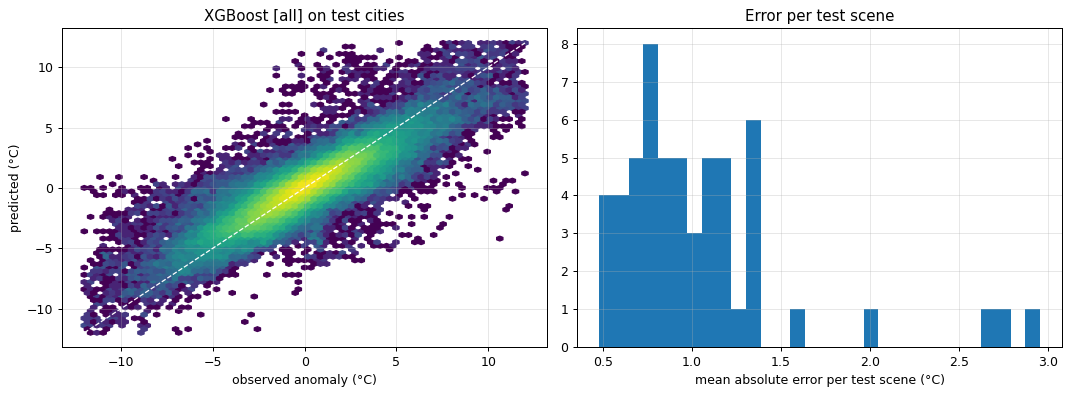

In [7]:
best = table[table.model == "xgb"].sort_values("test_r2").iloc[-1].features
cols = F.feature_sets(hs_cols)[best]
p = models[best].predict(X.loc[te, cols])
fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))
ax[0].hexbin(y[te], p, gridsize=70, bins="log", cmap="viridis", extent=(-12, 12, -12, 12))
ax[0].plot([-12, 12], [-12, 12], "w--", lw=1); ax[0].set_xlabel("observed anomaly (°C)"); ax[0].set_ylabel("predicted (°C)")
ax[0].set_title(f"XGBoost [{best}] on test cities")
err = pd.DataFrame({"pair": info.pair_id[te].to_numpy(), "abs_err": np.abs(p - y[te])}).groupby("pair").abs_err.mean()
ax[1].hist(err, bins=30); ax[1].set_xlabel("mean absolute error per test scene (°C)"); ax[1].set_title("Error per test scene")
for a in ax: a.grid(alpha=.3)
plt.tight_layout(); plt.show()

## For comparison: absolute LST

Same XGBoost with the day's weather (ERA5) and the raw thermal context level added. R² is much higher because most
absolute-LST variance is between scenes (hot vs cool days and climates), which weather explains well: a higher
number, but not the surface effect we want to explain.

In [8]:
cols = F.absolute_set(hs_cols)
m, _ = B.run("xgb_abs_all", "xgb", X[cols], info.y_abs.to_numpy(), info, RUNS, "absolute")
print({k: round(m["test"][k], 3) for k in ["mae", "rmse", "r2"]})

{'mae': 2.873, 'rmse': 3.944, 'r2': 0.798}


## Summary (test = cities never seen in training)

| Inputs | Best test R² | Test MAE (°C) |
|---|---|---|
| nothing (predict the scene median) | 0.00 | 2.18 |
| Landsat + built-up + terrain | 0.25–0.27 | 1.91 |
| + 4 hyperspectral indices | 0.26 | 1.92 |
| + all 122 hyperspectral bands | 0.28 | 1.88 |
| thermal context only | 0.73 | 1.05 |
| Landsat + thermal context | 0.74 | 1.05 |
| everything (Ridge) | **0.75** | **1.03** |

1. **Where a place is usually hot is the strongest predictor.** The thermal context alone explains 73 % of the
   within-city pattern in unseen cities: urban hot and cool spots are very stable over time.
2. **Hyperspectral adds a little over Landsat for prediction**: R² 0.25 → 0.28 from the surface alone, and nothing
   measurable once the thermal context is in. At 60 m most of the temperature signal is already in broad-band
   vegetation / built-up / water contrasts. This is an honest negative result worth reporting; hyperspectral's
   value is more in *explaining* (materials, albedo) than in raw accuracy, see `03_drivers`.
3. **A linear model is as good as trees** once the thermal context is included (Ridge 0.751 vs XGBoost 0.744),
   so the relationship is close to linear. RF is weaker with many correlated bands.
4. **Cold-climate cities are hardest** (R² ≈ 0.4); temperate cities are easiest (≈ 0.9).
5. Absolute LST with the day's weather reaches R² 0.80 but MAE 2.9 °C: the weather explains the level, not the
   pattern inside the city.

**Next:** CNNs on patches (do spatial neighbourhoods add to these pixel baselines?), then the fusion model.